# Enron Spam Dataset: Full Analysis, EDA and Cleaning

**Goal:** turn the raw Enron file into a clean file with exactly two columns:
- `email` : the email text
- `label` : 0 = ham (normal email), 1 = spam

**Input:** `raw/combined_enron_preprocessed.csv`
**Output:** `processed/enron_clean.csv`

Run one cell at a time and read the output before moving on.

## Phase 1: Load and understand the data

### Step 1: Import libraries and load the file

In [3]:
# pandas = main library for working with tables (called DataFrames)
import pandas as pd
# numpy = library for numbers and math
import numpy as np
# re = library for finding patterns in text (regular expressions)
import re
# os = library for working with folders
import os
# matplotlib = library for drawing charts
import matplotlib.pyplot as plt

# Read the CSV file into a table called "enron"
enron = pd.read_csv("../data/raw/combined_enron_preprocessed.csv")

# shape = (number of rows, number of columns)
print("Shape:", enron.shape)

Shape: (33702, 3)


### Step 2: Look at the structure

In [4]:
# info() shows column names, data types and how many values are not empty
enron.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33702 entries, 0 to 33701
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   label      33702 non-null  object
 1   label_num  33702 non-null  int64 
 2   text       33702 non-null  object
dtypes: int64(1), object(2)
memory usage: 790.0+ KB


In [4]:
# head() shows the first 5 rows so we can see what the data looks like
enron.head()

,label,label_num,text
0,ham,0,subject fw weather sites this is the list of w...
1,spam,1,subject i cant believe the changma wow wow wow...
2,spam,1,subject 4 color printing special request addit...
3,spam,1,subject nobody can beat us poloponybreakaway i...
4,ham,0,subject energy extravaganza 2 weeks away energ...


## Phase 2: Label analysis

### Step 3: Check that the two label columns agree
We have `label` (words: ham/spam) and `label_num` (numbers: 0/1).
They should always match. If they don't, we have a labeling error.

In [5]:
# crosstab counts how often each pair of values appears together
# Expected result: ham only with 0, spam only with 1 (other cells = 0)
pd.crosstab(enron["label"], enron["label_num"])

label_num,0,1
label,,
ham,16545,0
spam,0,17157


### Step 4: Check class balance (how many spam vs ham)

label
spam    17157
ham     16545
Name: count, dtype: int64

label
spam    0.509
ham     0.491
Name: proportion, dtype: float64


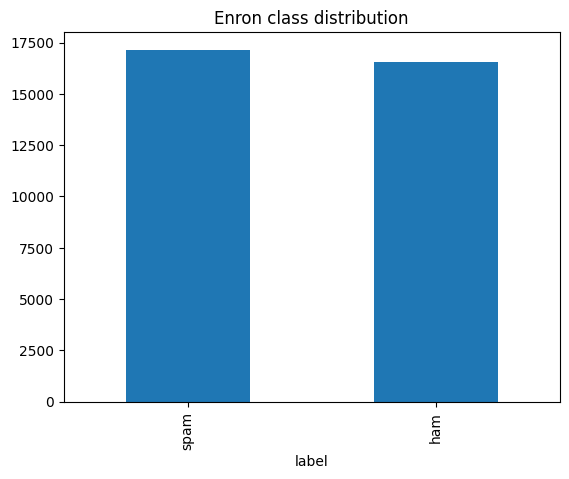

In [6]:
# Count of each class
print(enron["label"].value_counts())

# Same thing as a percentage (normalize=True gives fractions)
print()
print(enron["label"].value_counts(normalize=True).round(3))

# Draw a bar chart
enron["label"].value_counts().plot(kind="bar", title="Enron class distribution")
plt.show()

## Phase 3: Data quality checks

### Step 5: Missing and empty text

In [7]:
# isna().sum() counts empty (missing) values in each column
print("Missing values:")
print(enron.isna().sum())

# Also check for text that only has spaces (looks filled but is really empty)
print()
print("Empty/whitespace-only text:", (enron["text"].str.strip() == "").sum())

Missing values:
label        0
label_num    0
text         0
dtype: int64

Empty/whitespace-only text: 0


### Step 6: Duplicates and conflicting labels
- **Duplicate** = the same email appears more than once.
- **Conflict** = the same email text appears with BOTH labels (spam and ham).
  Conflicts are dangerous because a model cannot learn from contradicting answers.

In [8]:
# duplicated() marks every repeat after the first copy
print("Duplicate texts:", enron["text"].duplicated().sum())

# For each unique text, count how many different labels it has
conflict = enron.groupby("text")["label_num"].nunique()

# If a text has more than 1 label, it is a conflict
print("Texts with conflicting labels:", (conflict > 1).sum())

Duplicate texts: 3549
Texts with conflicting labels: 0


## Phase 4: Text EDA (Exploratory Data Analysis)

### Step 7: Email length analysis

In [9]:
# Work on a copy so we don't change the original table
eda = enron.copy()

# Number of characters in each email
eda["char_len"] = eda["text"].str.len()
# Number of words in each email (split on spaces, then count)
eda["word_len"] = eda["text"].str.split().str.len()

# describe() gives min, max, average and other summary numbers
print(eda[["char_len", "word_len"]].describe())

# Compare length of ham vs spam
print()
print(eda.groupby("label")["word_len"].describe())

            char_len      word_len
count   33702.000000  33702.000000
mean     1374.970120    242.126313
std      3972.542976    692.573820
min         8.000000      1.000000
25%       315.000000     56.000000
50%       637.500000    115.000000
75%      1396.000000    250.000000
max    211749.000000  37138.000000

         count        mean         std  min   25%    50%    75%      max
label                                                                   
ham    16545.0  276.387186  935.224766  2.0  57.0  133.0  274.0  37138.0
spam   17157.0  209.087544  310.751010  1.0  56.0  104.0  216.0   6005.0


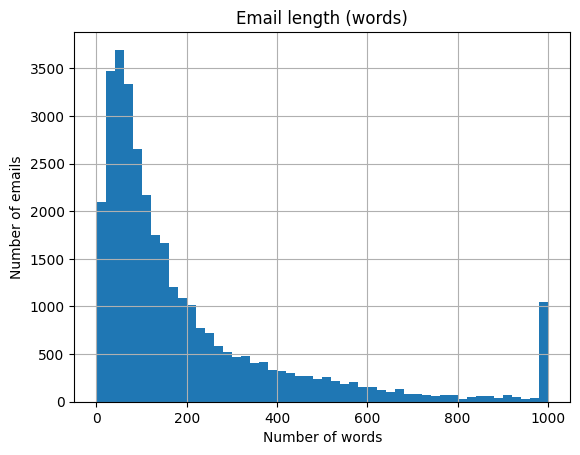

In [10]:
# Histogram of email lengths
# clip(upper=1000) squashes very long emails to 1000 so the chart stays readable
eda["word_len"].clip(upper=1000).hist(bins=50)
plt.title("Email length (words)")
plt.xlabel("Number of words")
plt.ylabel("Number of emails")
plt.show()

### Step 8: Read real examples
Never skip this. Looking at real emails tells you things numbers cannot.

In [11]:
# Print 3 random ham and 3 random spam emails (first 400 characters only)
for lbl in ["ham", "spam"]:
    print(f"\n===== {lbl.upper()} =====")
    samples = enron[enron["label"] == lbl]["text"].sample(3, random_state=1)
    for t in samples:
        print(t[:400])
        print("---")


===== HAM =====
subject preschedule path going real time for friday 07 20 01 7 20 hlh 19 mw bpa c 23634 epmi morgan pinw cps pplm snoh t bpap htsp 96092 nf pplm pplm failed to buy the transmission for friday this path will go real time our real time just needs to monitor and make sure pplm gets the tranny purchased and calls it in to bpa in a timely manner the saturday path is fine thanks donald 
---
subject job well done bob lee kenneth parkhill forwarded by stinson gibner hou ect on 02 28 2001 03 27 pm mario de la ossa enron 02 28 2001 03 26 pm to stinson gibner hou ect ect cc subject job well done bob lee kenneth parkhill just wanted to pass along my appreciation for the fine work these 2 gents are doing on the products model their attention to detail and customer focus has greatly facilita
---
subject re valuation steve please let me know when you come back i have detected a tendency to implement different approaches to valuation in the past to some extent it reflects the absence 

### Step 9: Look for noise
This tells us what cleaning is really needed.

In [12]:
# Each check gives True/False per email. mean() turns that into a percentage.
checks = {
    "contains url":      enron["text"].str.contains(r"http|www", regex=True),
    "contains digits":   enron["text"].str.contains(r"\d"),
    "non-ascii chars":   enron["text"].str.contains(r"[^\x00-\x7f]"),
    "html tags":         enron["text"].str.contains(r"<[^>]+>"),
    "starts w/ subject": enron["text"].str.startswith("subject"),
}

for name, mask in checks.items():
    print(f"{name:20s} {mask.mean():.1%}")

contains url         21.8%
contains digits      83.4%
non-ascii chars      3.2%
html tags            0.0%
starts w/ subject    100.0%


### Step 10: Most common words in ham vs spam

In [13]:
# Counter counts how many times each word appears
from collections import Counter

def top_words(series, n=15):
    # Join all emails into one long string, split into words, count them
    return Counter(" ".join(series).split()).most_common(n)

print("HAM :", top_words(enron[enron["label"] == "ham"]["text"]))
print()
print("SPAM:", top_words(enron[enron["label"] == "spam"]["text"]))

HAM : [('the', 182369), ('to', 129707), ('and', 83448), ('of', 77624), ('a', 65422), ('enron', 60906), ('in', 60677), ('for', 49828), ('on', 41696), ('is', 38242), ('i', 37123), ('s', 36225), ('that', 35646), ('ect', 35331), ('you', 34584)]

SPAM: [('the', 108354), ('to', 83271), ('and', 74013), ('of', 70805), ('a', 52630), ('you', 47471), ('in', 45895), ('this', 34839), ('for', 34584), ('your', 33871), ('is', 33288), ('that', 21201), ('with', 20385), ('i', 19337), ('be', 19336)]


## Phase 5: Preprocessing (cleaning)
Adjust the rules below based on what you saw in Steps 5 to 10.

### Step 11: Clean the data

In [14]:
# Make a copy so the original "enron" table stays untouched
df = enron.copy()

# 1. Remove rows with missing text
df = df.dropna(subset=["text"])

# 2. Remove rows where the text is only spaces
df = df[df["text"].str.strip() != ""]

# 3. Remove texts that have conflicting labels (both spam AND ham)
conflict = df.groupby("text")["label_num"].nunique()
conflict_texts = conflict[conflict > 1].index
df = df[~df["text"].isin(conflict_texts)]

# 4. Remove exact duplicate emails (keep the first copy)
df = df.drop_duplicates(subset="text")

# 5. Remove extremely short emails (fewer than 3 words = not useful)
#    Change the number 3 if Step 7 suggests a different cutoff
df = df[df["text"].str.split().str.len() >= 3]

# 6. Clean extra spaces (many spaces in a row become one)
df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()

print("Conflicting texts removed:", len(conflict_texts))
print("Rows before:", len(enron), "| Rows after:", len(df))

Conflicting texts removed: 0
Rows before: 33702 | Rows after: 30143


## Phase 6: Standardize and save

### Step 12: Build the final two-column dataset
We keep only the email text and the numeric label, and rename them to
the common names `email` and `label` so all 3 datasets match later.

In [15]:
enron_final = df[["text", "label_num"]].rename(
    columns={"text": "email", "label_num": "label"}
).reset_index(drop=True)   # reset_index gives clean row numbers 0,1,2...

print("Final shape:", enron_final.shape)
print(enron_final["label"].value_counts())
enron_final.head()

Final shape: (30143, 2)
label
0    15588
1    14555
Name: count, dtype: int64


,email,label
0,subject fw weather sites this is the list of w...,0
1,subject i cant believe the changma wow wow wow...,1
2,subject 4 color printing special request addit...,1
3,subject nobody can beat us poloponybreakaway i...,1
4,subject energy extravaganza 2 weeks away energ...,0


### Step 13: Save to a CSV file

In [16]:
# Create the "processed" folder if it does not exist yet
os.makedirs("processed", exist_ok=True)

# index=False means "don't write the row numbers into the file"
enron_final.to_csv("../data/processed/enron_clean.csv", index=False)
print("Saved: ../data/processed/enron_clean.csv")

Saved: ../data/processed/enron_clean.csv


In [5]:
enron.head()

,label,label_num,text
0,ham,0,subject fw weather sites this is the list of w...
1,spam,1,subject i cant believe the changma wow wow wow...
2,spam,1,subject 4 color printing special request addit...
3,spam,1,subject nobody can beat us poloponybreakaway i...
4,ham,0,subject energy extravaganza 2 weeks away energ...


## Done with Enron

Next: repeat the same phases for **SpamAssassin** (needs extra work to extract text from raw emails) and the **Synthetic** dataset, then combine all three.